In [15]:
import torch
from torch import nn
import sys
from pathlib import Path
from matplotlib import pyplot as plt

sys.path.insert(0, str(Path.cwd().parent))

import dl_utils

In [16]:
batch_size = 256
train_iter, test_iter = dl_utils.load_data_fashion_mnist(batch_size)


In [17]:
num_inputs, num_outputs, num_hiddens = 784, 10, 512

W1 = nn.Parameter(torch.randn(
    num_inputs, num_hiddens, requires_grad=True) * 0.01)
b1 = nn.Parameter(torch.zeros(num_hiddens, requires_grad=True))
W2 = nn.Parameter(torch.randn(
    num_hiddens, num_outputs, requires_grad=True) * 0.01)
b2 = nn.Parameter(torch.zeros(num_outputs, requires_grad= True))

params = [W1, b1, W2, b2]


In [18]:
def relu(X):
    a = torch.zeros_like(X)
    return torch.max(X, a)

In [19]:
def net(X):
    X = X.reshape((-1, num_inputs))
    H = relu(X@W1 + b1)
    return(H@W2 + b2)

In [20]:
loss = nn.CrossEntropyLoss(reduction='none')


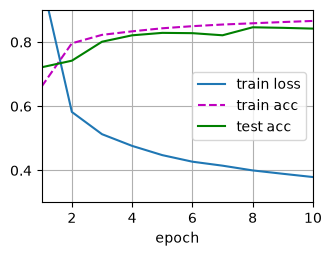

In [21]:
num_epochs, lr = 10, 0.1
updater = torch.optim.SGD(params, lr=lr)
dl_utils.train_ch3(net, train_iter, test_iter, loss, num_epochs, updater)

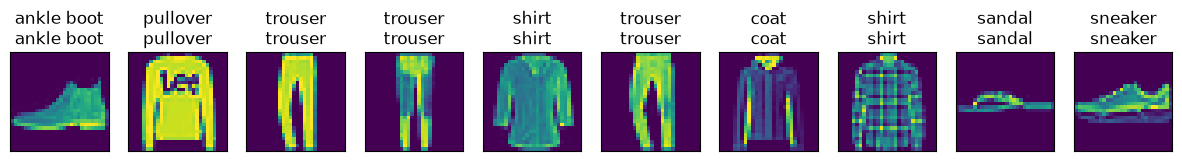

In [22]:
dl_utils.predict_ch3(net, test_iter, 10)

In [23]:
dl_utils.evaluate_accuracy(net,test_iter),type(test_iter)

(0.842, torch.utils.data.dataloader.DataLoader)